# Лабораторна робота №2 — Основи штучного інтелекту
### Варіант 9 · Регресія та лінійна класифікація

**Завдання з LMS:** ознайомитися з прикладами **№1, №2, №13** з методичних вказівок та розв'язати **задачі №1 і №5** (с. 54–56) за своїм варіантом.

Параметри з таблиці 3 для **варіанта №9**:

| `a` | `b` | `c` | `d` |
|---:|---:|---:|---:|
| 1 | 2 | 0 | 3 |

Усі приклади адаптовано до Python 3.11 і сучасної версії `scikit-learn`. Генерацію випадкового шуму в індивідуальних задачах зроблено **відтворюваною** (`seed=9`).

**Методичне джерело:** Копей В. Б., Онисько О. Р. *Основи штучного інтелекту: лабораторний практикум*. ІФНТУНГ, 2024, с. 5–8, 24–26, 54–56.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from pathlib import Path

A, B, C, D = 1, 2, 0, 3   # варіант 9
SEED = 9
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
print(f"Python / NumPy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}")
print(f"Варіант №9: a={A}, b={B}, c={C}, d={D}")

Python / NumPy 2.4.6; pandas 3.0.6; scikit-learn 1.9.1
Варіант №9: a=1, b=2, c=0, d=3


## 1. Приклад №1 — лінійна регресія (с. 5–6)

Дані взято **точно з прикладу №1** методичних вказівок. Алгоритм `LinearRegression` оцінює модель $\hat y = a x + b$. Виводимо параметри й $R^2$, візуалізуємо точки та пряму.

Коефіцієнт a = 1.020833
Вільний член b = 0.695833
R² = 0.896431


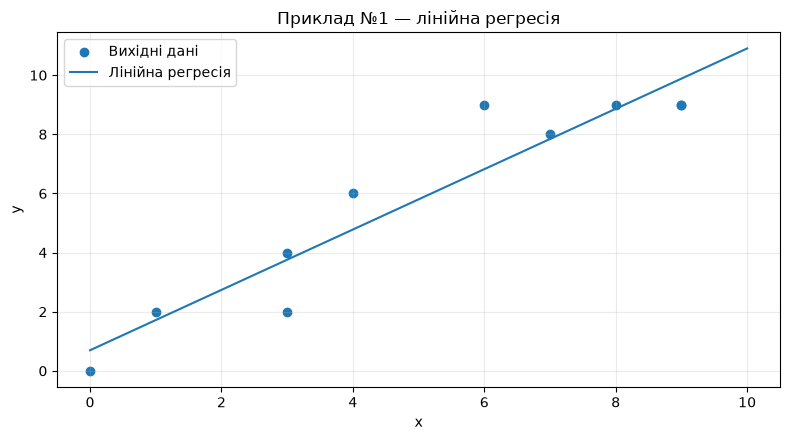

In [2]:
x1 = np.array([8, 0, 3, 4, 9, 7, 1, 6, 3, 9], dtype=float).reshape(-1, 1)
y1 = np.array([9, 0, 2, 6, 9, 8, 2, 9, 4, 9], dtype=float)
model1 = LinearRegression().fit(x1, y1)
print(f"Коефіцієнт a = {model1.coef_[0]:.6f}")
print(f"Вільний член b = {model1.intercept_:.6f}")
print(f"R² = {model1.score(x1, y1):.6f}")

X1 = np.linspace(0, 10, 100).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x1[:, 0], y1, label="Вихідні дані")
ax.plot(X1[:, 0], model1.predict(X1), label="Лінійна регресія")
ax.set(xlabel="x", ylabel="y", title="Приклад №1 — лінійна регресія")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(OUT / "01_example_linear_regression.png", dpi=160)
plt.show()

## 2. Приклад №2 — двовимірна лінійна регресія (с. 7–8)

Маємо дві ознаки $x_0$ і $x_1$. Модель шукає площину $\hat y = a x_0+b x_1+c$ за дев'ятьма точками. Дані відтворено з методички.

a=1.833333, b=1.833333, c=-1.111111
R² = 0.743852


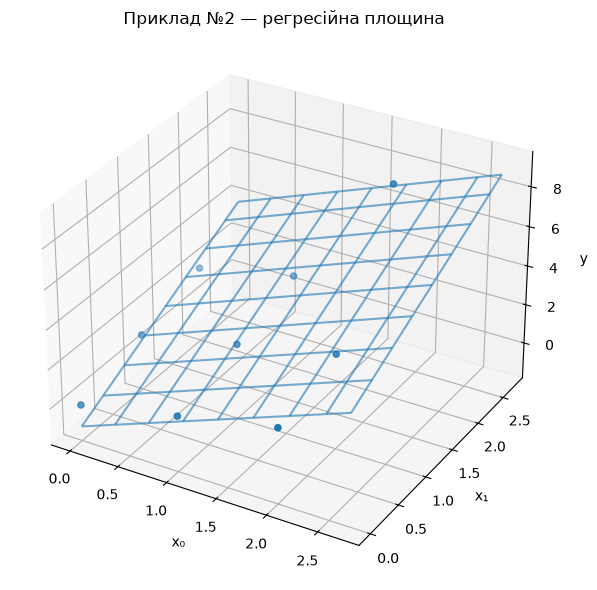

In [3]:
x2 = np.array([[0, 1, 2, 0, 1, 2, 0, 1, 2],
               [0, 0, 0, 1, 1, 1, 2, 2, 2]], dtype=float).T
y2 = np.array([0, 1, 2, 1, 2, 3, 2, 3, 9], dtype=float)
model2 = LinearRegression().fit(x2, y2)
print(f"a={model2.coef_[0]:.6f}, b={model2.coef_[1]:.6f}, c={model2.intercept_:.6f}")
print(f"R² = {model2.score(x2, y2):.6f}")

u2, v2 = np.meshgrid(np.linspace(0, 2.7, 24), np.linspace(0, 2.7, 24))
z2 = model2.predict(np.column_stack([u2.ravel(), v2.ravel()])).reshape(u2.shape)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x2[:, 0], x2[:, 1], y2, label="Емпіричні точки")
ax.plot_wireframe(u2, v2, z2, rstride=3, cstride=3, alpha=0.6)
ax.set(xlabel="x₀", ylabel="x₁", zlabel="y", title="Приклад №2 — регресійна площина")
fig.tight_layout(); fig.savefig(OUT / "02_example_2d_regression.png", dpi=160)
plt.show()

## 3. Приклад №13 — лінійна класифікація (с. 24–26)

Методичка демонструє `LogisticRegression(C=100)` для двох класів (0 і 1) та двох ознак. Спочатку покажемо матрицю розсіювання, потім знайдемо межу рішень і прогноз у точці `(5, 10)`.

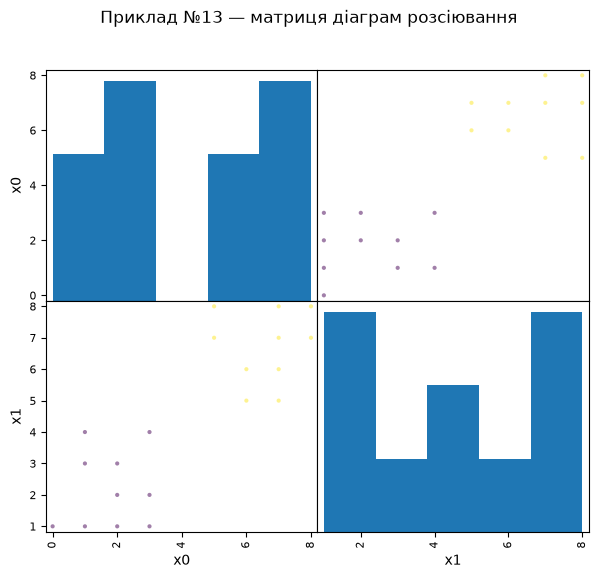

Коефіцієнти: [[2.689624 1.765113]] вільний член: [-19.767539]
Прогноз для (5, 10): клас 1
Перевірка знаку лінійної функції: True


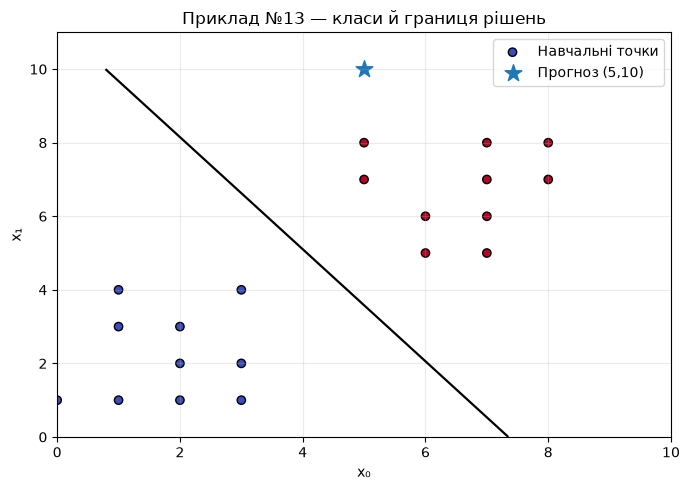

In [4]:
x13 = np.array([[0, 1, 1, 2, 2, 3, 2, 3, 1, 3, 6, 5, 6, 7, 7, 8, 7, 7, 8, 5],
                [1, 1, 3, 1, 2, 2, 3, 4, 4, 1, 5, 7, 6, 7, 6, 7, 5, 8, 8, 8]], dtype=float).T
y13 = np.array([0]*10 + [1]*10)

pd.plotting.scatter_matrix(pd.DataFrame(x13, columns=["x0", "x1"]),
                           c=y13, figsize=(7, 6), hist_kwds={"bins": 5}, diagonal="hist")
plt.suptitle("Приклад №13 — матриця діаграм розсіювання")
plt.savefig(OUT / "03_example_scatter_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

model13 = LogisticRegression(C=100, max_iter=2000).fit(x13, y13)
p13 = np.array([[5.0, 10.0]])
print("Коефіцієнти:", model13.coef_.round(6), "вільний член:", model13.intercept_.round(6))
print(f"Прогноз для (5, 10): клас {model13.predict(p13)[0]}")
print("Перевірка знаку лінійної функції:", bool(model13.decision_function(p13)[0] > 0))

u13, v13 = np.meshgrid(np.linspace(0, 10, 200), np.linspace(0, 10, 200))
mesh13 = np.column_stack([u13.ravel(), v13.ravel()])
d13 = model13.decision_function(mesh13).reshape(u13.shape)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(x13[:, 0], x13[:, 1], c=y13, cmap="coolwarm", edgecolors="black", label="Навчальні точки")
ax.contour(u13, v13, d13, levels=[0], colors="black", linewidths=1.6)
ax.scatter(p13[:, 0], p13[:, 1], marker="*", s=160, label="Прогноз (5,10)")
ax.set(xlabel="x₀", ylabel="x₁", title="Приклад №13 — класи й границя рішень")
ax.set_xlim(0, 10); ax.set_ylim(0, 11); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "04_example_classification_boundary.png", dpi=160)
plt.show()

## 4. Індивідуальна задача №1 — варіант 9 (с. 54–55)

За умовою: `x = np.arange(0, 20)`, $y = a x + b + \varepsilon$, де $\varepsilon\sim N(0, 1+c)$. Для варіанта 9: **a=1, b=2, c=0**, отже $y = x + 2 + \varepsilon$ з `sigma=1`. Щоб графіки відтворювались, використовуємо `default_rng(9)`.

Потрібно визначити коефіцієнти, $R^2$, прогноз у довільній точці та побудувати графік.

Формула генерації: y = 1·x + 2 + N(0, 1)
Знайдено: a=1.060440; b=1.591347
Коефіцієнт детермінації R²=0.971551
Прогноз у x=10.5: y=12.725967


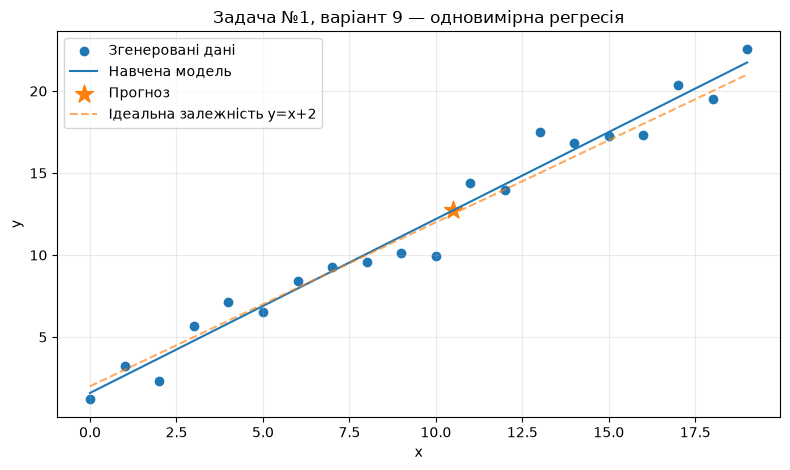

In [5]:
rng1 = np.random.default_rng(SEED)
x_task1_raw = np.arange(0, 20, dtype=float)
y_task1 = A * x_task1_raw + B + rng1.normal(0, 1 + C, x_task1_raw.size)
x_task1 = x_task1_raw.reshape(-1, 1)
model_task1 = LinearRegression().fit(x_task1, y_task1)
point_task1 = np.array([[10.5]])
prediction_task1 = float(model_task1.predict(point_task1)[0])
print(f"Формула генерації: y = {A}·x + {B} + N(0, {1+C})")
print(f"Знайдено: a={model_task1.coef_[0]:.6f}; b={model_task1.intercept_:.6f}")
print(f"Коефіцієнт детермінації R²={model_task1.score(x_task1, y_task1):.6f}")
print(f"Прогноз у x={point_task1[0,0]:g}: y={prediction_task1:.6f}")

line1 = np.linspace(0, 19, 200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(x_task1_raw, y_task1, label="Згенеровані дані")
ax.plot(line1[:, 0], model_task1.predict(line1), label="Навчена модель")
ax.scatter(point_task1[:,0], [prediction_task1], marker="*", s=180, label="Прогноз")
ax.plot(line1[:,0], A * line1[:,0] + B, linestyle="--", alpha=0.65, label="Ідеальна залежність y=x+2")
ax.set(xlabel="x", ylabel="y", title="Задача №1, варіант 9 — одновимірна регресія")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(OUT / "05_task1_variant09.png", dpi=160)
plt.show()

## 5. Індивідуальна задача №5 — варіант 9 (с. 56)

За методичкою 25 точок на сітці $5\times 5$:

$$z = a x_0 + b x_1 + c + \varepsilon, \quad \varepsilon\sim N(0, 1+d), \quad y=\mathbb{1}[z>\bar z]$$

Для варіанта 9: **a=1, b=2, c=0, d=3**, тобто стандартне відхилення шуму **4**. Навчаємо лінійний класифікатор `LogisticRegression` на навчальній частині даних і обчислюємо **метрики на тестовій частині**, щоб не завищувати якість. Побудуємо границю рішень та прогноз у точці `(2.5, 2.5)`.

Класи: {np.int64(0): np.int64(14), np.int64(1): np.int64(11)}
Навчальних точок: 17 тестових: 8
Коефіцієнти: [[2.087559 1.675949]] вільний член: [-9.331757]
Прогноз для точки (2.5, 2.5): клас 1
Accuracy: 0.3750
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
Матриця помилок:
 [[3 1]
 [4 0]]
Детальний звіт:
               precision    recall  f1-score   support

           0       0.43      0.75      0.55         4
           1       0.00      0.00      0.00         4

    accuracy                           0.38         8
   macro avg       0.21      0.38      0.27         8
weighted avg       0.21      0.38      0.27         8



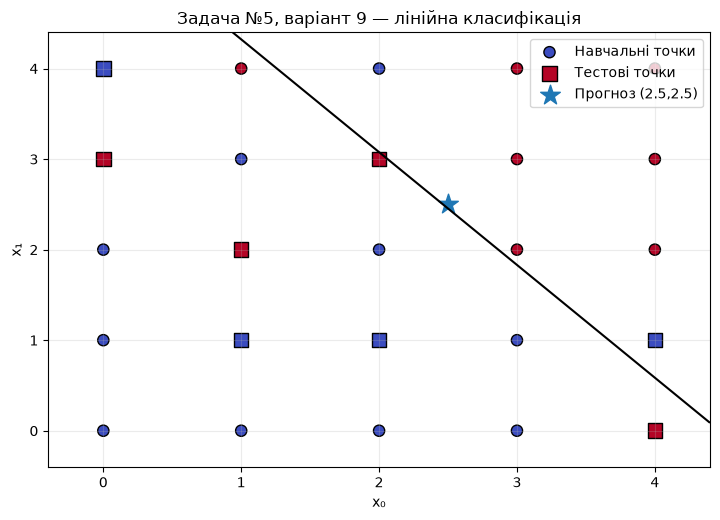

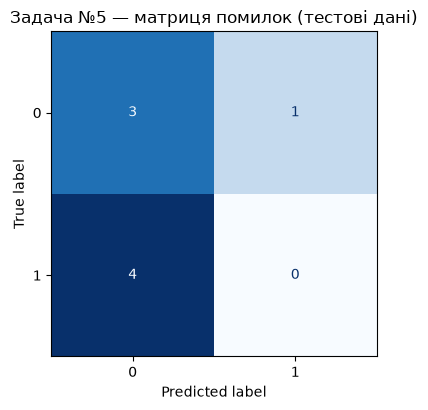

In [6]:
u5, v5 = np.meshgrid(np.arange(5), np.arange(5))
x_task5 = np.column_stack([u5.ravel(), v5.ravel()]).astype(float)
rng5 = np.random.default_rng(SEED)
z_task5 = A*x_task5[:,0] + B*x_task5[:,1] + C + rng5.normal(0, 1+D, len(x_task5))
y_task5 = (z_task5 > z_task5.mean()).astype(int)
print(f"Класи: {dict(zip(*np.unique(y_task5, return_counts=True)))}")

X_train5, X_test5, y_train5, y_test5 = train_test_split(
    x_task5, y_task5, test_size=0.32, random_state=SEED, stratify=y_task5
)
model_task5 = LogisticRegression(C=100, max_iter=2000).fit(X_train5, y_train5)
y_pred5 = model_task5.predict(X_test5)
point_task5 = np.array([[2.5, 2.5]])
prediction_task5 = int(model_task5.predict(point_task5)[0])
print("Навчальних точок:", len(X_train5), "тестових:", len(X_test5))
print("Коефіцієнти:", model_task5.coef_.round(6), "вільний член:", model_task5.intercept_.round(6))
print(f"Прогноз для точки (2.5, 2.5): клас {prediction_task5}")
print(f"Accuracy: {accuracy_score(y_test5, y_pred5):.4f}")
print(f"Precision: {precision_score(y_test5, y_pred5, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test5, y_pred5, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test5, y_pred5, zero_division=0):.4f}")
print("Матриця помилок:\n", confusion_matrix(y_test5, y_pred5, labels=[0, 1]))
print("Детальний звіт:\n", classification_report(y_test5, y_pred5, zero_division=0))

u, v = np.meshgrid(np.linspace(-0.4, 4.4, 240), np.linspace(-0.4, 4.4, 240))
mesh = np.column_stack([u.ravel(), v.ravel()])
decision = model_task5.decision_function(mesh).reshape(u.shape)
fig, ax = plt.subplots(figsize=(7.3, 5.3))
ax.scatter(X_train5[:,0], X_train5[:,1], c=y_train5, cmap="coolwarm", edgecolors="black", s=65, label="Навчальні точки")
ax.scatter(X_test5[:,0], X_test5[:,1], c=y_test5, cmap="coolwarm", edgecolors="black", s=110, marker="s", label="Тестові точки")
ax.contour(u, v, decision, levels=[0], colors="black", linewidths=1.5)
ax.scatter(point_task5[:,0], point_task5[:,1], marker="*", s=220, label="Прогноз (2.5,2.5)")
ax.set(xlabel="x₀", ylabel="x₁", title="Задача №5, варіант 9 — лінійна класифікація")
ax.grid(alpha=0.25); ax.legend(loc="best")
fig.tight_layout(); fig.savefig(OUT / "06_task5_variant09_boundary.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test5, y_pred5, labels=[0, 1], ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Задача №5 — матриця помилок (тестові дані)")
fig.tight_layout(); fig.savefig(OUT / "07_task5_variant09_confusion.png", dpi=160)
plt.show()

## 6. ВИСНОВОК

Під час лабораторної роботи досліджено методи одновимірної та двовимірної лінійної регресії, а також логістичну регресію для бінарної класифікації. Розглянуто приклади №1, №2 і №13 з методичних вказівок.

Для варіанта №9 розв'язано задачу №1: побудовано регресійну модель, визначено її коефіцієнти та коефіцієнт детермінації, виконано прогноз і побудовано графік. У задачі №5 побудовано двовимірну модель класифікації, обчислено метрики на тестовій вибірці та показано межу прийняття рішень.

Регресійні моделі у прикладах оцінювалися на навчальних даних, як у методичних вказівках. Для класифікації застосовано окрему тестову вибірку. Через невеликий обсяг даних (25 точок) якість класифікації може залежати від розбиття вибірки; фіксоване зерно генератора забезпечує відтворюваність експерименту.
